# Projet F1 : Risque de crédit en Allemagne

**Module :** Science des données appliquée à la finance

**Sujet :** Classification du risque de crédit

**Source des données :** UCI Machine Learning Repository – German Credit Data (UCI 144)

**Objectif :** Identifier les clients présentant un mauvais risque de crédit à partir de leurs caractéristiques personnelles et des informations relatives à leur prêt.

# Nouvelle section 1. Introduction et problématique
## 1. Introduction et problématique

L'octroi de crédit représente une activité importante pour les établissements financiers. Cependant, il comporte un risque : certains clients peuvent ne pas être en mesure de rembourser leurs prêts.

L'objectif de ce projet est de construire un modèle de classification permettant de distinguer les bons et les mauvais risques de crédit à partir des caractéristiques des clients et des prêts.

Une attention particulière sera accordée aux coûts des erreurs de classification, car accepter un client présentant un mauvais risque peut entraîner des pertes financières importantes.

## 2. Présentation du jeu de données

Dans le cadre de ce projet, nous utilisons le jeu de données *German Credit Data*, disponible sur le dépôt UCI Machine Learning Repository (UCI 144).

Ce jeu de données contient :
- **1 000 observations** correspondant à des dossiers de crédit.
- **20 variables** décrivant les caractéristiques des clients et leurs prêts.
- **300 mauvais risques de crédit**.

La variable cible permet de distinguer deux catégories :
- Les bons risques de crédit.
- Les mauvais risques de crédit.

Ce jeu de données permet donc de réaliser une classification binaire afin d'évaluer la capacité des modèles à identifier les clients présentant un risque de crédit élevé.

## 3. Analyse exploratoire des données (EDA)

L'analyse exploratoire des données constitue une étape essentielle avant la construction des modèles de classification.

Elle permet de mieux comprendre la structure du jeu de données, d'étudier les caractéristiques des clients et d'identifier les éventuelles anomalies.

Cette analyse portera principalement sur :

- L'examen de la structure et des dimensions du jeu de données.
- L'identification des types de variables.
- La recherche des valeurs manquantes.
- L'étude de la distribution de la variable cible.
- L'analyse de la répartition des variables catégorielles et numériques.

L'objectif est de mieux comprendre les données afin de préparer correctement les étapes suivantes.

## 4. Préparation des données (Preprocessing)

La préparation des données consiste à transformer le jeu de données afin de le rendre exploitable par les algorithmes de Machine Learning.

Dans ce projet, plusieurs opérations seront nécessaires :

- **Encodage des variables catégorielles :** transformer les informations qualitatives en valeurs numériques.
- **Standardisation des variables numériques :** mettre les variables telles que les montants et les durées sur une échelle comparable.
- **Séparation des données :** diviser le jeu de données en deux ensembles, un ensemble d'entraînement (training set) et un ensemble de test (testing set).

Ces opérations permettront de préparer les données pour la construction et l'évaluation des modèles de classification.

## 5. Modélisation (Machine Learning)

Après la préparation des données, nous passons à la construction des modèles de classification.

L'objectif est de comparer plusieurs algorithmes afin de déterminer lequel permet de mieux identifier les clients présentant un mauvais risque de crédit.

Les trois modèles étudiés sont :

**1. Régression logistique (Logistic Regression)**

Un algorithme de classification qui estime la probabilité qu'un client appartienne à une catégorie, bon ou mauvais risque de crédit.

**2. Arbre de décision (Decision Tree)**

Un modèle qui prend des décisions successives à partir des caractéristiques des clients afin de les classer.

**3. Forêt aléatoire (Random Forest)**

Un ensemble de plusieurs arbres de décision qui combine leurs prédictions afin d'obtenir une classification plus robuste.

Les performances de ces trois modèles seront comparées afin de sélectionner le modèle le plus adapté à la problématique du risque de crédit.

## 6. Évaluation des modèles

Après l'entraînement des modèles, il est nécessaire d'évaluer leurs performances afin de comparer leur capacité à identifier les bons et les mauvais risques de crédit.

Plusieurs indicateurs seront utilisés :

**1. Matrice de confusion (Confusion Matrix)**

Elle permet de comparer les prédictions du modèle avec les résultats réels et d'identifier les bonnes et les mauvaises classifications.

**2. AUC (Area Under the ROC Curve)**

Cet indicateur mesure la capacité du modèle à distinguer les bons risques des mauvais risques. Plus sa valeur est proche de 1, meilleure est sa capacité de discrimination.

**3. Coût des erreurs de classification**

Dans le domaine du crédit, les erreurs n'ont pas toutes les mêmes conséquences financières. Une mauvaise décision peut entraîner une perte importante pour l'établissement prêteur.

La comparaison des modèles tiendra donc compte à la fois de leurs performances statistiques et de leurs coûts financiers.

## 7. Optimisation du seuil de décision et du coût financier

Dans le domaine du risque de crédit, les erreurs de classification peuvent entraîner des conséquences financières différentes pour l'établissement prêteur.

Le seuil de décision permet de déterminer à partir de quelle probabilité un client sera considéré comme présentant un mauvais risque de crédit.

Par défaut, les modèles de classification utilisent souvent un seuil de 0,5. Cependant, ce seuil n'est pas nécessairement le plus adapté à notre problématique.

L'objectif est donc de tester plusieurs seuils de décision afin de trouver celui qui minimise le coût total des erreurs de classification.

Cette étape prendra en compte :
- Le coût des faux positifs.
- Le coût des faux négatifs.
- L'évolution du coût total selon le seuil choisi.
- L'analyse de sensibilité du modèle.

Le seuil optimal sera sélectionné en fonction du coût financier total et non uniquement de la performance statistique.

## 8. Conclusion

Ce projet a pour objectif de développer un modèle de Machine Learning capable de prédire le risque de crédit en Allemagne.

À travers les différentes étapes, nous allons explorer et préparer les données, construire plusieurs modèles de classification et comparer leurs performances.

Une attention particulière sera accordée aux coûts asymétriques des erreurs de classification et à l'optimisation du seuil de décision.

Le modèle final sera sélectionné en tenant compte de sa capacité à distinguer les bons et les mauvais risques de crédit ainsi que de son coût financier.

Enfin, les résultats permettront de montrer l'intérêt des méthodes de Data Science dans l'aide à la décision financière, tout en tenant compte des limites des modèles prédictifs.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("Bibliothèques importées avec succès !")


Bibliothèques importées avec succès !


In [3]:
import zipfile
import os

# Extraction du fichier ZIP contenant les données
zip_path = "/content/statlog+german+credit+data (1).zip"
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/")
    print("Archive extraite avec succès !")
else:
    print("Attention : Le fichier ZIP est introuvable. Veuillez vérifier son emplacement.")

columns = [
    "checking_status", "duration", "credit_history",
    "purpose", "credit_amount", "savings_status",
    "employment", "installment_rate", "personal_status",
    "other_parties", "residence_since", "property_magnitude",
    "age", "other_payment_plans", "housing",
    "existing_credits", "job", "num_dependents",
    "own_telephone", "foreign_worker", "class"
]

# Lecture du dataset maintenant extrait
df = pd.read_csv(
    "/content/german.data",
    sep=" ",
    header=None,
    names=columns
)

print("Dimensions du dataset :", df.shape)
display(df.head())

Archive extraite avec succès !
Dimensions du dataset : (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [4]:

print("Dimensions :", df.shape)

print("\nInformations sur les variables :")
df.info()

print("\nValeurs manquantes :")
print(df.isnull().sum().sum())

print("\nRépartition de la variable cible :")
print(df["class"].value_counts())


Dimensions : (1000, 21)

Informations sur les variables :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   checking_status      1000 non-null   object
 1   duration             1000 non-null   int64 
 2   credit_history       1000 non-null   object
 3   purpose              1000 non-null   object
 4   credit_amount        1000 non-null   int64 
 5   savings_status       1000 non-null   object
 6   employment           1000 non-null   object
 7   installment_rate     1000 non-null   int64 
 8   personal_status      1000 non-null   object
 9   other_parties        1000 non-null   object
 10  residence_since      1000 non-null   int64 
 11  property_magnitude   1000 non-null   object
 12  age                  1000 non-null   int64 
 13  other_payment_plans  1000 non-null   object
 14  housing              1000 non-null   object
 15

In [5]:

# Définir la variable cible
y = df["class"].map({1: 0, 2: 1})

# Sélectionner les variables explicatives
X = df.drop(columns=["class"])

# Séparer les données
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Taille des données d'entraînement :", X_train.shape)
print("Taille des données de test :", X_test.shape)

print("\nRépartition des classes dans l'entraînement :")
print(y_train.value_counts())

print("\nRépartition des classes dans le test :")
print(y_test.value_counts())


Taille des données d'entraînement : (800, 20)
Taille des données de test : (200, 20)

Répartition des classes dans l'entraînement :
class
0    560
1    240
Name: count, dtype: int64

Répartition des classes dans le test :
class
0    140
1     60
Name: count, dtype: int64


In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identifier les variables numériques et catégorielles
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object", "category"]).columns

# Préparer les transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Ajuster sur les données d'entraînement
X_train_processed = preprocessor.fit_transform(X_train)

# Appliquer les mêmes transformations aux données de test
X_test_processed = preprocessor.transform(X_test)

print("Dimensions après transformation :")
print("Entraînement :", X_train_processed.shape)
print("Test :", X_test_processed.shape)

print("Prétraitement terminé avec succès !")


Dimensions après transformation :
Entraînement : (800, 61)
Test : (200, 61)
Prétraitement terminé avec succès !


In [7]:

from sklearn.linear_model import LogisticRegression

# Créer le modèle
log_model = LogisticRegression(max_iter=1000, random_state=42)

# Entraîner le modèle
log_model.fit(X_train_processed, y_train)

# Prédire les classes
y_pred_log = log_model.predict(X_test_processed)

# Calculer les probabilités d'un mauvais risque
y_proba_log = log_model.predict_proba(X_test_processed)[:, 1]

print("Régression logistique entraînée avec succès !")


Régression logistique entraînée avec succès !


In [8]:

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Calcul de l'AUC
auc_log = roc_auc_score(y_test, y_proba_log)

# Matrice de confusion
cm_log = confusion_matrix(y_test, y_pred_log)

# Accuracy
acc_log = accuracy_score(y_test, y_pred_log)

print("AUC :", round(auc_log, 3))
print("Accuracy :", round(acc_log, 3))

print("\nMatrice de confusion :")
print(cm_log)

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_log))


AUC : 0.804
Accuracy : 0.78

Matrice de confusion :
[[124  16]
 [ 28  32]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       140
           1       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200



In [9]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# Séparer les données d'entraînement en apprentissage et validation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Construire un pipeline sans fuite de données
validation_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Entraîner sur la partie apprentissage
validation_model.fit(X_fit, y_fit)

# Obtenir les probabilités de mauvais risque sur validation
y_val_proba = validation_model.predict_proba(X_val)[:, 1]

print("Apprentissage :", X_fit.shape)
print("Validation :", X_val.shape)
print("Modèle de validation prêt !")


Apprentissage : (600, 20)
Validation : (200, 20)
Modèle de validation prêt !


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Tester plusieurs seuils
thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:
    # Prédictions selon le seuil
    y_val_pred = (y_val_proba >= threshold).astype(int)

    # Calculer les erreurs
    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    # Calcul du coût financier
    total_cost = 5 * fn + fp

    results.append({
        "Seuil": round(threshold, 2),
        "Faux positifs": fp,
        "Faux négatifs": fn,
        "Coût total": total_cost
    })

# Afficher les résultats
cost_table = pd.DataFrame(results)
display(cost_table)

# Identifier le meilleur seuil
best_row = cost_table.loc[cost_table["Coût total"].idxmin()]

best_threshold = best_row["Seuil"]
best_cost = best_row["Coût total"]

print("Meilleur seuil :", best_threshold)
print("Coût minimal :", best_cost)


,Seuil,Faux positifs,Faux négatifs,Coût total
0,0.10,88,3,103
1,0.15,76,7,111
2,0.20,63,13,128
3,0.25,56,17,141
4,0.30,48,22,158
5,0.35,45,25,170
6,0.40,41,30,191
7,0.45,34,33,199
8,0.50,27,34,197
9,0.55,24,36,204


Meilleur seuil : 0.1
Coût minimal : 103.0


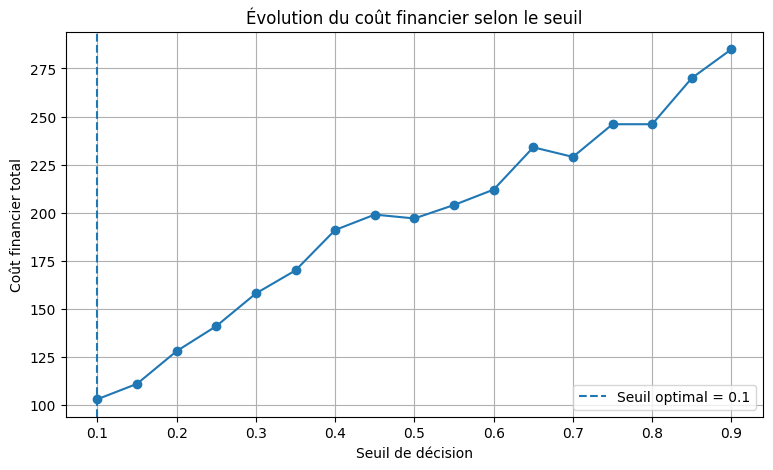

In [11]:

plt.figure(figsize=(9, 5))

plt.plot(
    cost_table["Seuil"],
    cost_table["Coût total"],
    marker="o"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Seuil optimal = {best_threshold}"
)

plt.xlabel("Seuil de décision")
plt.ylabel("Coût financier total")
plt.title("Évolution du coût financier selon le seuil")
plt.legend()
plt.grid(True)
plt.show()


Seuil optimal : 0.1
Coût minimal : 103


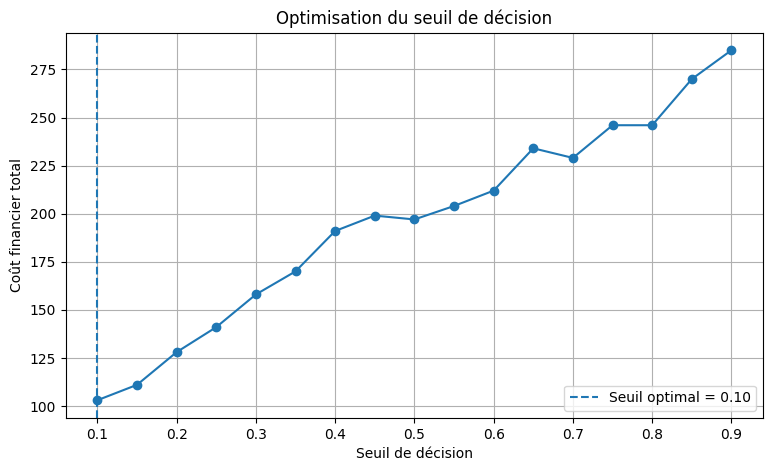

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Définir les coûts des erreurs
cost_FP = 1
cost_FN = 5

# Tester plusieurs seuils
thresholds = np.arange(0.10, 0.91, 0.05)

costs = []

for threshold in thresholds:

    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    total_cost = cost_FP * fp + cost_FN * fn

    costs.append(total_cost)

# Identifier le seuil optimal
best_index = np.argmin(costs)
best_threshold = thresholds[best_index]
best_cost = costs[best_index]

print("Seuil optimal :", round(best_threshold, 2))
print("Coût minimal :", best_cost)

# Tracer la courbe du coût
plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs, marker="o")
plt.axvline(best_threshold, linestyle="--",
            label=f"Seuil optimal = {best_threshold:.2f}")
plt.xlabel("Seuil de décision")
plt.ylabel("Coût financier total")
plt.title("Optimisation du seuil de décision")
plt.legend()
plt.grid()
plt.show()


In [13]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    accuracy_score
)

# Prédire les probabilités sur le jeu de test
y_test_proba = validation_model.predict_proba(
    X_test
)[:, 1]

# Appliquer le seuil optimal
y_test_pred = (y_test_proba >= best_threshold).astype(int)

# Calculer les indicateurs
cm = confusion_matrix(y_test, y_test_pred)

tn, fp, fn, tp = cm.ravel()

final_cost = cost_FP * fp + cost_FN * fn

print("Seuil utilisé :", best_threshold)
print("AUC :", round(roc_auc_score(y_test, y_test_proba), 3))
print("Accuracy :", round(accuracy_score(y_test, y_test_pred), 3))

print("\nMatrice de confusion :")
print(cm)

print("\nRapport de classification :")
print(classification_report(y_test, y_test_pred))

print("Coût financier final :", final_cost)


Seuil utilisé : 0.1
AUC : 0.782
Accuracy : 0.515

Matrice de confusion :
[[50 90]
 [ 7 53]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.88      0.36      0.51       140
           1       0.37      0.88      0.52        60

    accuracy                           0.52       200
   macro avg       0.62      0.62      0.51       200
weighted avg       0.73      0.52      0.51       200

Coût financier final : 125


Nouveau seuil optimal : 0.11
Nouveau coût minimal : 100


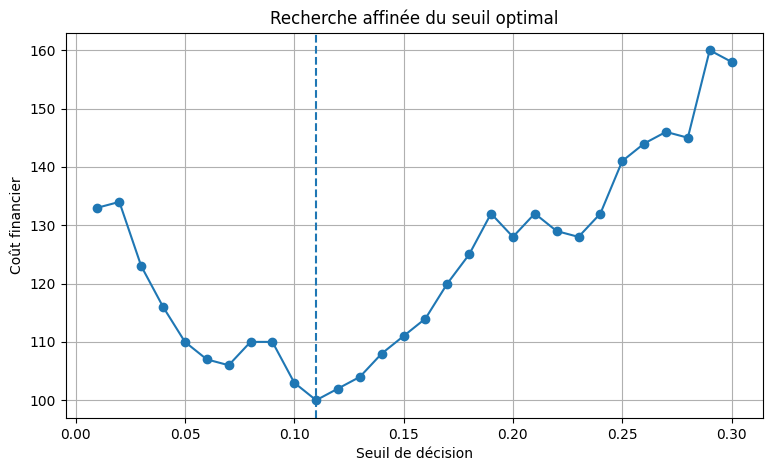

In [14]:

# Tester des seuils plus faibles sur la validation
thresholds_fine = np.arange(0.01, 0.31, 0.01)

costs_fine = []

for threshold in thresholds_fine:
    pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    costs_fine.append(cost_FP * fp + cost_FN * fn)

best_idx_fine = np.argmin(costs_fine)

best_threshold_fine = thresholds_fine[best_idx_fine]
best_cost_fine = costs_fine[best_idx_fine]

print("Nouveau seuil optimal :", round(best_threshold_fine, 2))
print("Nouveau coût minimal :", best_cost_fine)

plt.figure(figsize=(9, 5))
plt.plot(thresholds_fine, costs_fine, marker="o")
plt.axvline(best_threshold_fine, linestyle="--")
plt.xlabel("Seuil de décision")
plt.ylabel("Coût financier")
plt.title("Recherche affinée du seuil optimal")
plt.grid()
plt.show()



In [15]:

# Appliquer le nouveau seuil optimal
y_test_pred_fine = (
    y_test_proba >= best_threshold_fine
).astype(int)

# Calculer la matrice de confusion
cm_fine = confusion_matrix(y_test, y_test_pred_fine)

tn, fp, fn, tp = cm_fine.ravel()

# Calculer le coût financier
final_cost_fine = cost_FP * fp + cost_FN * fn

print("Seuil final :", round(best_threshold_fine, 2))
print("AUC :", round(roc_auc_score(y_test, y_test_proba), 3))
print("Accuracy :", round(accuracy_score(y_test, y_test_pred_fine), 3))

print("\nMatrice de confusion :")
print(cm_fine)

print("\nRapport de classification :")
print(classification_report(y_test, y_test_pred_fine))

print("Coût financier final :", final_cost_fine)


Seuil final : 0.11
AUC : 0.782
Accuracy : 0.53

Matrice de confusion :
[[53 87]
 [ 7 53]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.88      0.38      0.53       140
           1       0.38      0.88      0.53        60

    accuracy                           0.53       200
   macro avg       0.63      0.63      0.53       200
weighted avg       0.73      0.53      0.53       200

Coût financier final : 122


In [16]:
# Analyse de sensibilité selon le coût des erreurs

cout_refus_bon = 1
cout_acceptation_mauvais = [3, 5, 10]

seuils = np.arange(0.01, 0.51, 0.01)

resultats_sensibilite = []

for cout_mauvais in cout_acceptation_mauvais:

    couts = []

    for seuil in seuils:
        predictions = (y_val_proba >= seuil).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        cout_total = cout_refus_bon * fp + cout_mauvais * fn
        couts.append(cout_total)

    meilleur_indice = np.argmin(couts)

    resultats_sensibilite.append({
        "Coût acceptation mauvais risque": cout_mauvais,
        "Seuil optimal": seuils[meilleur_indice],
        "Coût minimal validation": couts[meilleur_indice]
    })

df_sensibilite = pd.DataFrame(resultats_sensibilite)
display(df_sensibilite)

,Coût acceptation mauvais risque,Seuil optimal,Coût minimal validation
0,3,0.11,94
1,5,0.11,100
2,10,0.06,112


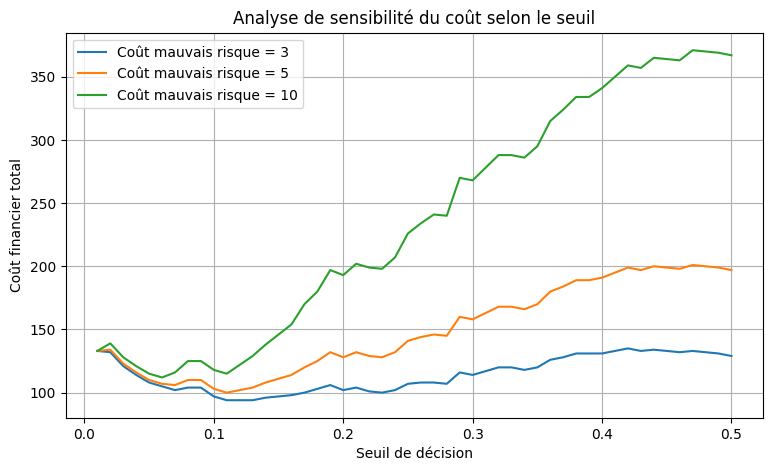

In [17]:
plt.figure(figsize=(9, 5))

for cout_mauvais in [3, 5, 10]:

    couts = []

    for seuil in seuils:
        predictions = (y_val_proba >= seuil).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        cout_total = fp + cout_mauvais * fn
        couts.append(cout_total)

    plt.plot(seuils, couts, label=f"Coût mauvais risque = {cout_mauvais}")

plt.xlabel("Seuil de décision")
plt.ylabel("Coût financier total")
plt.title("Analyse de sensibilité du coût selon le seuil")
plt.legend()
plt.grid(True)
plt.show()

La courbe représente l'évolution du coût financier total en fonction du seuil de décision pour trois hypothèses de coûts (3, 5 et 10).

On constate que le coût financier varie selon le seuil choisi. Un seuil plus faible permet de détecter davantage de mauvais risques, mais peut également entraîner le refus de bons clients.

L'analyse montre que le seuil optimal dépend directement des hypothèses financières retenues. Il est donc important de trouver un équilibre entre la réduction des pertes liées aux mauvais crédits et la limitation des refus injustifiés

## Conclusion générale

Ce projet avait pour objectif d'identifier les attributs des clients et des prêts permettant de détecter les mauvais risques de crédit à partir du jeu de données German Credit Data de l'UCI.

Après une première analyse des données, un prétraitement a été réalisé afin de préparer les variables à la modélisation. Les variables catégorielles ont été encodées et les variables numériques standardisées.

Une régression logistique a été utilisée comme modèle de référence. Les résultats obtenus sur les données de test présentent une AUC de **0,782**, ce qui montre une capacité de discrimination intéressante entre les bons et les mauvais risques.

L'étude du seuil de décision a montré que le seuil standard de 0,5 n'est pas nécessairement le plus adapté lorsque les erreurs ont des conséquences financières différentes. L'analyse de sensibilité a également démontré que le seuil optimal varie selon le coût attribué aux erreurs.

Ainsi, la prise en compte des coûts financiers permet d'adapter les décisions de crédit aux objectifs de la banque. Ce projet montre l'intérêt du Machine Learning dans la gestion du risque de crédit, tout en soulignant l'importance du choix des hypothèses financières et du seuil de décision.

In [18]:
# Modèle 2 : Arbre de décision
tree_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_fit, y_fit)

tree_proba = tree_model.predict_proba(X_val)[:, 1]
tree_pred = (tree_proba >= 0.11).astype(int)


# Modèle 3 : Forêt aléatoire
forest_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

forest_model.fit(X_fit, y_fit)

forest_proba = forest_model.predict_proba(X_val)[:, 1]
forest_pred = (forest_proba >= 0.11).astype(int)


# Comparaison des modèles
modeles = {
    "Régression logistique": y_val_proba,
    "Arbre de décision": tree_proba,
    "Forêt aléatoire": forest_proba
}

comparaison = []

for nom, probabilites in modeles.items():
    predictions = (probabilites >= 0.11).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    auc = roc_auc_score(y_val, probabilites)
    cout = fp + 5 * fn

    comparaison.append({
        "Modèle": nom,
        "AUC": round(auc, 3),
        "Coût total": cout
    })

df_comparaison = pd.DataFrame(comparaison)
display(df_comparaison)

,Modèle,AUC,Coût total
0,Régression logistique,0.726,100
1,Arbre de décision,0.655,129
2,Forêt aléatoire,0.749,133


### Comparaison et interprétation des modèles

Les résultats montrent que la forêt aléatoire présente la meilleure performance en termes d'AUC, avec une valeur de 0,749. Elle possède donc une meilleure capacité de discrimination entre les bons et les mauvais risques parmi les trois modèles étudiés.

La régression logistique obtient une AUC de 0,726 et présente le coût financier total le plus faible, avec 100. Elle constitue donc le meilleur choix lorsque l'objectif prioritaire est de limiter les coûts liés aux erreurs de classification.

L'arbre de décision présente les performances les plus faibles, avec une AUC de 0,655 et un coût total de 129.

En conclusion, la régression logistique offre le meilleur compromis financier dans cette comparaison, tandis que la forêt aléatoire présente la meilleure performance statistique selon l'AUC.

# 9. Déclaration d'utilisation de l'intelligence artificielle

Dans le cadre de ce projet intitulé « Risque de crédit en Allemagne », ChatGPT (OpenAI) a été utilisé comme outil d'assistance.

Son utilisation a principalement concerné :
- La compréhension des étapes du projet de Machine Learning.
- L'aide à l'écriture et à la correction du code Python.
- Les explications concernant le prétraitement des données et les modèles de classification.
- L'interprétation des résultats obtenus, notamment l'AUC, la matrice de confusion et le coût des erreurs.
- L'aide à la structuration et à la rédaction du rapport.

Les codes proposés ont été exécutés sur Google Colab et les résultats ont été vérifiés à partir du jeu de données German Credit Data.

L'intelligence artificielle a été utilisée comme un outil d'accompagnement et d'apprentissage. La responsabilité du travail final, de la vérification des résultats et de la compréhension des méthodes utilisées reste celle de l'étudiante.